# Application 07 · How accurate is a math-library polynomial?

**Builds on:** [Lecture 07](../notebooks/07_better_enclosures.ipynb) (mean-value form, subdivision) and Lecture 05 (Arb balls).

**Time:** about 60 minutes. **You will certify:** an upper bound on the worst-case error of the polynomial that replaces sin x on a reduced argument range.

Math libraries do not call a magic `sin`. After argument reduction, they evaluate a short polynomial p(x) on a small interval. The library is correct only if the *approximation error* sup|sin x − p(x)| over that whole interval is below the target accuracy. Checking a few thousand sample points is not enough. Tools such as Sollya certify this supremum with the same ideas as Lecture 07.

## Google Colab setup — run this cell first

**Local Jupyter:** this cell skips Colab setup; use your installed course environment.

Use a **CPU Python runtime** (Python 3.12 or newer). Run the next cell and select
**vc_runtime.zip** from this edition when prompted. It loads the course helpers
and installs the arithmetic libraries. Repeat setup whenever you get a new runtime.
No Drive mounting or local Python installation is required.
Use this setup instead of the local installation and kernel-selection instructions
in the original course text.

Save a copy of this notebook in Drive, or download it after editing. Files created
by the project are under `/content/validated-course/build/certificates/`; download
those separately from Colab's Files panel. Runtime files are temporary.

Open other course notebooks using **File → Upload notebook**, choosing them from
the extracted course folder. Relative course links are intended for local Jupyter
and do not open sibling notebooks automatically in Colab.


In [1]:
try:
    import google.colab
except ImportError:
    print("Local Jupyter: using the installed course environment.")
else:
    import hashlib
    from pathlib import Path
    import subprocess
    import sys
    from google.colab import files

    if sys.version_info < (3, 12):
        raise RuntimeError("This course needs a Python 3.12 or newer Colab runtime.")

    # Upload the small companion file supplied with the Colab course edition.
    expected_hash = '833652c4a440f1c3a22bc6e68c59d533b41e6f9f1ff0b4af226f8fbee2244c1a'
    runtime_zip = Path("/content") / ("vc-course-" + expected_hash + ".zip")
    if not runtime_zip.exists():
        print("Select vc_runtime.zip from the extracted Colab course folder.")
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Upload only vc_runtime.zip, then run this cell again.")
        archive_bytes = next(iter(uploaded.values()))
        if hashlib.sha256(archive_bytes).hexdigest() != expected_hash:
            raise ValueError("Wrong vc_runtime.zip: use the one supplied with this notebook.")
        runtime_zip.write_bytes(archive_bytes)

    if hashlib.sha256(runtime_zip.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("The cached vc archive has changed; start a fresh runtime.")

    # Keep Colab's existing NumPy and plotting stack when they satisfy these bounds.
    # Install MPFR/Arb bindings, not the full local Jupyter environment.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        'numpy>=1.26', 'matplotlib>=3.8', 'gmpy2==2.3.1', 'python-flint==0.9.0', 'jupytext>=1.16'
    ])
    import gmpy2
    import flint
    if gmpy2.version() != "2.3.1" or flint.__version__ != "0.9.0":
        raise RuntimeError("Old arithmetic libraries are still loaded. Restart the session and run setup first.")

    if str(runtime_zip) not in sys.path:
        sys.path.insert(0, str(runtime_zip))

    import vc
    if not vc.__file__.startswith(str(runtime_zip) + "/"):
        raise RuntimeError("Another vc copy is already loaded. Start a fresh runtime.")

    # Preserve the relative output paths used by the project notebooks.
    import os
    working_folder = Path("/content/validated-course") / 'applications'
    working_folder.mkdir(parents=True, exist_ok=True)
    os.chdir(working_folder)
    print("Course helpers ready:", vc.__version__)

Local Jupyter: using the installed course environment.


In [2]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from flint import fmpq
from vc.intervals import RationalInterval as Interval
from vc.enclosures import subdivide, mean_value
from vc.arb_bridge import evaluate_ball

## 1 · The polynomial and the question

Take the degree-7 Taylor polynomial

$$p(x)=x-\frac{x^3}{6}+\frac{x^5}{120}-\frac{x^7}{5040}$$

on the domain D = [0, 4/5]. It contains the usual reduced range [0, π/4], because π/4 < 0.7854 < 0.8. We store the coefficients as exact fractions (index = power of x). Derivative coefficients are computed from them, so p′ and p″ cannot disagree with p.

In [3]:
coefficients = [Fraction(0), Fraction(1), Fraction(0), Fraction(-1, 6),
                Fraction(0), Fraction(1, 120), Fraction(0), Fraction(-1, 5040)]

def differentiate(coeffs):
    return [power * c for power, c in enumerate(coeffs)][1:]

first_derivative = differentiate(coefficients)
second_derivative = differentiate(first_derivative)

def polynomial(coeffs, x):
    """Horner evaluation on an Arb ball x with exact rational coefficients."""
    total = x * 0
    for c in reversed(coeffs):
        total = total * x + fmpq(c.numerator, c.denominator)
    return total

domain = Interval(0, Fraction(4, 5))
print("p'(x) coefficients:", first_derivative)

p'(x) coefficients: [Fraction(1, 1), Fraction(0, 1), Fraction(-1, 2), Fraction(0, 1), Fraction(1, 24), Fraction(0, 1), Fraction(-1, 720)]


The error function and its first two derivatives are

$$e(x)=\sin x-p(x),\qquad e'(x)=\cos x-p'(x),\qquad e''(x)=-\sin x-p''(x).$$

Each evaluator below receives a *rational interval*, encloses it in an Arb ball, and returns a rational interval containing every value on that interval (Lecture 05).

In [4]:
PRECISION = 80

def error(X):
    return evaluate_ball(lambda x: x.sin() - polynomial(coefficients, x), X, PRECISION)

def error_slope(X):
    return evaluate_ball(lambda x: x.cos() - polynomial(first_derivative, x), X, PRECISION)

def error_curvature(X):
    return evaluate_ball(lambda x: -x.sin() - polynomial(second_derivative, x), X, PRECISION)

## 2 · What sampling tells us, and what it does not

Sampling 10 001 points in binary64 suggests a maximum error near 3.68·10⁻⁷, at the right endpoint. This is evidence, not a bound: the maximum could hide between samples. A sample *does* give a rigorous **lower** bound if we evaluate it with Arb at an exact point.

In [5]:
xs = np.linspace(0, 0.8, 10001)
float_poly = sum(float(c) * xs**k for k, c in enumerate(coefficients))
sampled = np.abs(np.sin(xs) - float_poly)
print(f"Largest sampled error: {sampled.max():.6e} at x = {xs[sampled.argmax()]:.4f}")

lower_bound = error(Interval(Fraction(4, 5))).lo
print(f"Certified lower bound for the supremum: {float(lower_bound):.6e}")

Largest sampled error: 3.677249e-07 at x = 0.8000
Certified lower bound for the supremum: 3.677249e-07


## 3 · Natural evaluation fails: cancellation of two enclosures

On a piece X of width h, sin(X) and p(X) are each enclosed with width about h, because both functions have slope near 1. Their difference is ~10⁻⁷, but interval subtraction *adds* widths (Lecture 06). The enclosure of e(X) therefore has width ≈ 2h, however accurate each part is.

To beat 10⁻⁷ by natural evaluation we would need h ≈ 10⁻⁷, so about ten million pieces.

In [6]:
def certified_supremum(bound, pieces):
    """Largest |e| allowed by valid enclosures on a covering of the domain."""
    largest = Fraction(0)
    for piece in pieces:
        enclosure = bound(piece)
        largest = max(largest, abs(enclosure.lo), abs(enclosure.hi))
    return largest

for depth in [4, 8, 12]:
    pieces = subdivide(domain, depth)
    print(f"{len(pieces):5d} pieces: natural bound {float(certified_supremum(error, pieces)):.3e}")

   16 pieces: natural bound 5.001e-02
  256 pieces: natural bound 3.125e-03


 4096 pieces: natural bound 1.953e-04


## 4 · The mean-value form removes the cancellation

The mean value theorem gives, for the midpoint m of X,

$$e(X)\subseteq e(m)+e'(X)\,(X-m).$$

Now the large parts sin and p only enter through the **point** value e(m), which Arb computes sharply. The interval part involves e′(X), which is small. But natural evaluation of e′ = cos − p′ suffers the same cancellation, with width ≈ h. The total width is then ≈ h², not h.

**Second step.** Apply the same idea to e′:

$$e'(X)\subseteq e'(m)+e''(X)\,(X-m).$$

This nested form is a second-order Taylor bound with a rigorous remainder. Its width is ≈ h³ plus the true variation of e on X.

In [7]:
def first_order(X):
    return mean_value(error, error_slope, X)

def nested_slope(X):
    return mean_value(error_slope, error_curvature, X)

def second_order(X):
    return mean_value(error, nested_slope, X)

methods = {"natural": error, "mean value": first_order, "nested mean value": second_order}
depths = [2, 4, 6, 8, 10]
results = {name: [] for name in methods}
for depth in depths:
    pieces = subdivide(domain, depth)
    for name, bound in methods.items():
        results[name].append(certified_supremum(bound, pieces))

print("pieces   natural      mean value   nested")
for i, depth in enumerate(depths):
    row = [f"{float(results[name][i]):.3e}" for name in methods]
    print(f"{2**depth:6d}   " + "    ".join(row))

pieces   natural      mean value   nested
     4   2.007e-01    1.441e-02    2.007e-03
    16   5.001e-02    9.374e-04    3.126e-05
    64   1.250e-02    5.944e-05    8.114e-07
   256   3.125e-03    4.069e-06    3.747e-07
  1024   7.813e-04    5.993e-07    3.678e-07


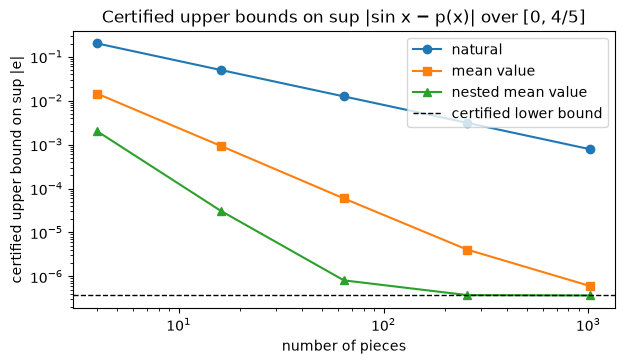

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
counts = [2**depth for depth in depths]
for name, marker in zip(methods, ["o", "s", "^"]):
    ax.loglog(counts, [float(v) for v in results[name]], marker=marker, label=name)
ax.axhline(float(lower_bound), color="black", linestyle="--", linewidth=1,
           label="certified lower bound")
ax.set(xlabel="number of pieces", ylabel="certified upper bound on sup |e|",
       title="Certified upper bounds on sup |sin x − p(x)| over [0, 4/5]")
ax.legend()
plt.close(fig)
display(fig)

## 5 · The certified statement

With 1024 pieces the nested form gives an upper bound, and the point x = 4/5 gives a lower bound. Together:

In [9]:
upper_bound = results["nested mean value"][-1]
print(f"sup over [0, 4/5] of |sin x - p(x)| lies in [{float(lower_bound):.7e}, {float(upper_bound):.7e}]")
print(f"Relative gap: {float((upper_bound - lower_bound) / lower_bound):.2%}")
binary32_ulp = Fraction(1, 2**24)   # spacing of binary32 numbers in [1/2, 1)
print(f"In units of one binary32 ulp near sin(4/5) = 0.717: {float(upper_bound / binary32_ulp):.1f}")

sup over [0, 4/5] of |sin x - p(x)| lies in [3.6772492e-07, 3.6783577e-07]
Relative gap: 0.03%
In units of one binary32 ulp near sin(4/5) = 0.717: 6.2


**Premises behind the claim.** The pieces cover D exactly (exact rational bisection). Every evaluator returns a valid enclosure (Arb balls, Lecture 05). The mean value theorem applies because sin − p is smooth. Sampling contributed nothing to the upper bound.

**Engineering reading.** Near x = 4/5 the error is about six binary32 ulps. So this polynomial is not accurate enough even for single precision on the whole range, and far from enough for binary64. A library would use a higher degree, a smaller range, or a minimax polynomial (Exercise 2). The certified bound tells you which choice works; sampling cannot.

## 6 · Where it fails: working precision

The derivative tricks remove the *dependency* overestimation. They cannot remove Arb's rounding: every ball has a radius of about 2⁻ᵖʳᵉᶜ relative to its size. If the precision is too low, the bound stalls at the rounding level, no matter how many pieces we use.

In [10]:
pieces = subdivide(domain, 7)
for bits in [20, 30, 53, 80]:
    PRECISION = bits
    print(f"{bits:3d} bits: nested bound with 128 pieces = {float(certified_supremum(second_order, pieces)):.4e}")
PRECISION = 80

 20 bits: nested bound with 128 pieces = 5.7803e-06
 30 bits: nested bound with 128 pieces = 4.2610e-07
 53 bits: nested bound with 128 pieces = 4.2317e-07
 80 bits: nested bound with 128 pieces = 4.2317e-07


At 20 bits the result is a valid but useless bound: the ball radii (~10⁻⁶) dominate the error we want to measure. Choosing the precision is part of the certificate design.

## Exercises

1. **Degree 5.** Drop the x⁷ term. Find (by certified bounds) the largest b of the form k/20 such that sup over [0, b] of |sin x − p₅(x)| < 2⁻²⁴.
2. **Beat Taylor.** Change the x⁷ coefficient slightly, e.g. to −1/5100. Certify whether the new polynomial has a smaller maximum error on [0, 4/5]. Why can a non-Taylor polynomial be better on an interval? (Search for "minimax approximation".)
3. **Stored coefficients.** A real library stores binary64 coefficients. Replace each coefficient c by `Fraction.from_float(float(c))` and certify the change in the error bound. Is coefficient rounding significant here?
4. **Adaptive pieces.** Use `vc.enclosures.adaptive_range` with `second_order` as evaluator. How many pieces does it need for a 1% relative gap, compared with uniform subdivision? Where does it put them?